In [154]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style= "darkgrid", color_codes = True)
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense, Flatten, Dropout, Input
from keras.regularizers import l2
import warnings
warnings.filterwarnings('ignore')

# Vérifier si GPU est disponible
if tf.config.list_physical_devices('GPU'):
    # Permettre la croissance de la mémoire GPU
    for gpu in tf.config.experimental.list_physical_devices('GPU'):
        tf.config.experimental.set_memory_growth(gpu, True)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

GPU disponible: []


In [155]:
# Define image size and other parameters
img_width, img_height = 128, 128
batchsize = 32
epochs = 6
num_of_class = 2
def create_three_class_dataset(directory, batch_size, img_size):
    # Créer une liste de tous les fichiers
    import os
    
    normal_path = os.path.join(directory, 'NORMAL')
    pneumonia_path = os.path.join(directory, 'PNEUMONIA')
    
    # Préparer les listes de fichiers et leurs labels
    normal_files = [(f, [1,0,0]) for f in os.listdir(normal_path) if f.endswith(('.jpeg', '.jpg', '.png'))]
    pneumonia_files = []
    for f in os.listdir(pneumonia_path):
        if f.endswith(('.jpeg', '.jpg', '.png')):
            if 'virus' in f.lower():
                pneumonia_files.append((f, [0,1,0]))  # Viral
            elif 'bacteria' in f.lower():
                pneumonia_files.append((f, [0,0,1]))  # Bacterial
    
    # Fonction pour charger et prétraiter une image
    def load_and_preprocess_image(file_path):
        img = tf.io.read_file(file_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, img_size)
        img = img / 255.0  # Normalisation
        return img
    
    # Créer les datasets séparés
    normal_dataset = tf.data.Dataset.from_tensor_slices(
        ([os.path.join(normal_path, f[0]) for f in normal_files],
         [f[1] for f in normal_files]))
    
    pneumonia_dataset = tf.data.Dataset.from_tensor_slices(
        ([os.path.join(pneumonia_path, f[0]) for f in pneumonia_files],
         [f[1] for f in pneumonia_files]))
    
    # Combiner les datasets
    dataset = normal_dataset.concatenate(pneumonia_dataset)
    
    # Mapper pour charger les images
    dataset = dataset.map(lambda x, y: (load_and_preprocess_image(x), y))
    
    # Mélanger et créer les batches
    dataset = dataset.shuffle(buffer_size=1000)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    
    return dataset

# Charger les datasets
img_size = (img_width, img_height)
train = create_three_class_dataset('chest_xray/train', batchsize, img_size)
validation = create_three_class_dataset('chest_xray/val', batchsize, img_size)
test = create_three_class_dataset('chest_xray/test', batchsize, img_size)

# Vérifier la forme des données
for images, labels in train.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Sample labels:", labels[0])  # Devrait montrer un vecteur one-hot de taille 3

Images shape: (32, 128, 128, 3)
Labels shape: (32, 3)
Sample labels: tf.Tensor([1 0 0], shape=(3,), dtype=int32)


Format des labels: [1 0 0]
Label 0: [1.0, 0.0, 0.0]
Label 1: [1.0, 0.0, 0.0]
Label 2: [1.0, 0.0, 0.0]
Label 3: [1.0, 0.0, 0.0]


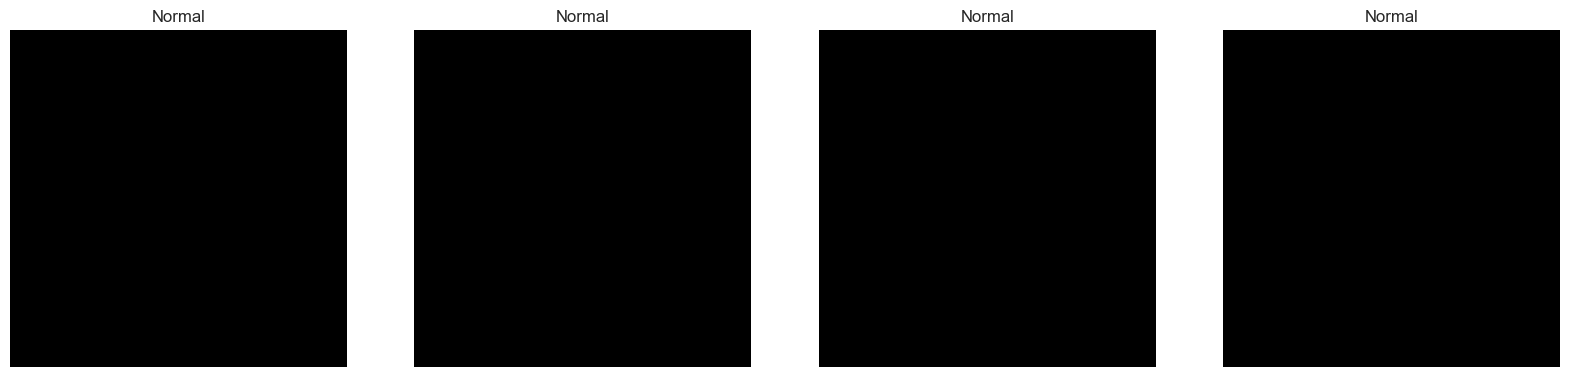

In [156]:
data_iterator = train.as_numpy_iterator()
batch = data_iterator.next()

# Afficher un exemple de label pour debug
print("Format des labels:", batch[1][0])

# Créer un dictionnaire pour convertir les labels one-hot en texte
label_dict = {
    '[1.0, 0.0, 0.0]': "Normal",
    '[0.0, 1.0, 0.0]': "Viral Pneumonia",
    '[0.0, 0.0, 1.0]': "Bacterial Pneumonia"
}

fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    # Convertir le label en string avec le bon format
    label_str = str([float(x) for x in batch[1][idx].tolist()])
    print(f"Label {idx}:", label_str)  # Debug
    label = label_dict.get(label_str, "Unknown")
    ax[idx].title.set_text(label)
    ax[idx].axis('off')

plt.show()

In [157]:
from tensorflow.keras.utils import to_categorical
# Définir une taille fixe pour toutes les images
IMG_SIZE = (128, 128)  # Taille standard pour VGG16

# Extracting Features and Labels
x_train = []
y_train = []
x_val = []
y_val = []
x_test = []
y_test = []

# Fonction pour traiter un batch
def process_batch(batch):
    features, labels = batch
    features = tf.image.resize(features, IMG_SIZE)
    return features.numpy(), labels.numpy()

# Traiter les données d'entraînement
for batch in train:
    features, labels = process_batch(batch)
    x_train.extend(features)
    y_train.extend(labels)

# Traiter les données de test
for batch in test:
    features, labels = process_batch(batch)
    x_test.extend(features)
    y_test.extend(labels)

# Traiter les données de validation
for batch in validation:
    features, labels = process_batch(batch)
    x_val.extend(features)
    y_val.extend(labels)

# Convertir en arrays numpy
x_train = np.array(x_train, dtype=np.float32)
x_val = np.array(x_val, dtype=np.float32)
x_test = np.array(x_test, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

# Normaliser les images
x_train = tf.image.resize(x_train, IMG_SIZE)
x_val = tf.image.resize(x_val, IMG_SIZE)
x_test = tf.image.resize(x_test, IMG_SIZE)

# Vérifier les shapes
print("Shape de x_train:", x_train.shape)
print("Shape de y_train:", y_train.shape)
print("Shape de x_val:", x_val.shape)
print("Shape de y_val:", y_val.shape)
print("Shape de x_test:", x_test.shape)
print("Shape de y_test:", y_test.shape)

# Vérifier les valeurs uniques dans les labels
print("\nValeurs uniques dans y_train:", np.unique(y_train, axis=0))

Shape de x_train: (5216, 128, 128, 3)
Shape de y_train: (5216, 3)
Shape de x_val: (16, 128, 128, 3)
Shape de y_val: (16, 3)
Shape de x_test: (624, 128, 128, 3)
Shape de y_test: (624, 3)

Valeurs uniques dans y_train: [[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]


In [158]:
# check the shapes of 'x_train' and 'y_train':
print("Shape of 'x_train':", x_train.shape)
print("Shape of 'y_train':", y_train.shape)
print("Shape of 'x_val':", x_val.shape)
print("Shape of 'y_val':", y_val.shape)
print("Shape of 'x_test':", x_test.shape)
print("Shape of 'y_test':", y_test.shape)

Shape of 'x_train': (5216, 128, 128, 3)
Shape of 'y_train': (5216, 3)
Shape of 'x_val': (16, 128, 128, 3)
Shape of 'y_val': (16, 3)
Shape of 'x_test': (624, 128, 128, 3)
Shape of 'y_test': (624, 3)


In [159]:
def create_model():
    base_model = VGG16(weights='imagenet', 
                      include_top=False, 
                      input_shape=(128, 128, 3))
    
    # Dégeler seulement les dernières couches
    for layer in base_model.layers[:-6]:  # Geler plus de couches sauf les 6 dernières
        layer.trainable = False
    
    model = Sequential([
        base_model,
        Flatten(),
        Dropout(0.4),
        Dense(256, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        Dense(3, activation='softmax')
    ])
    
    # Learning rate plus faible pour un meilleur apprentissage
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)
    
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy', 'Precision', 'Recall']
    )
    
    return model

Fold 1/5
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - Precision: 0.7098 - Recall: 0.5961 - accuracy: 0.6570 - loss: 6.3691 - val_Precision: 0.8121 - val_Recall: 0.7826 - val_accuracy: 0.7941 - val_loss: 4.0972 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - Precision: 0.8144 - Recall: 0.7939 - accuracy: 0.8040 - loss: 3.7638 - val_Precision: 0.8131 - val_Recall: 0.8084 - val_accuracy: 0.8113 - val_loss: 2.9970 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - Precision: 0.8251 - Recall: 0.8115 - accuracy: 0.8214 - loss: 2.8135 - val_Precision: 0.8338 - val_Recall: 0.8218 - val_accuracy: 0.8295 - val_loss: 2.4220 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - Precision: 0.8378 - Recall: 0.8258 - accuracy: 0.8345 - loss: 2.2914 - val_Precision: 0.7942 - val_Recall: 0.7874 - val_accuracy: 0.7902 - val_loss: 2.1101 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━

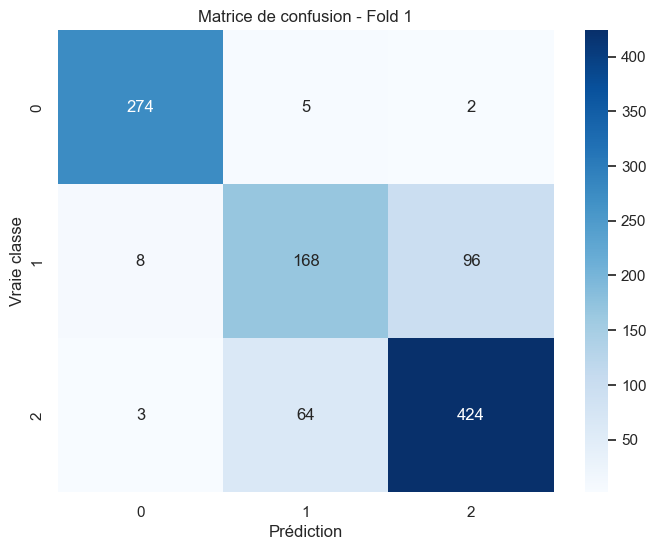

Fold 2/5
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - Precision: 0.6916 - Recall: 0.5975 - accuracy: 0.6626 - loss: 6.3258 - val_Precision: 0.7708 - val_Recall: 0.7546 - val_accuracy: 0.7641 - val_loss: 3.9682 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - Precision: 0.7977 - Recall: 0.7725 - accuracy: 0.7853 - loss: 3.6289 - val_Precision: 0.8419 - val_Recall: 0.8169 - val_accuracy: 0.8303 - val_loss: 2.8028 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - Precision: 0.8151 - Recall: 0.8004 - accuracy: 0.8072 - loss: 2.6647 - val_Precision: 0.8329 - val_Recall: 0.8265 - val_accuracy: 0.8293 - val_loss: 2.2611 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - Precision: 0.8299 - Recall: 0.8180 - accuracy: 0.8245 - loss: 2.1683 - val_Precision: 0.8431 - val_Recall: 0.8245 - val_accuracy: 0.8389 - val_loss: 1.9340 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━

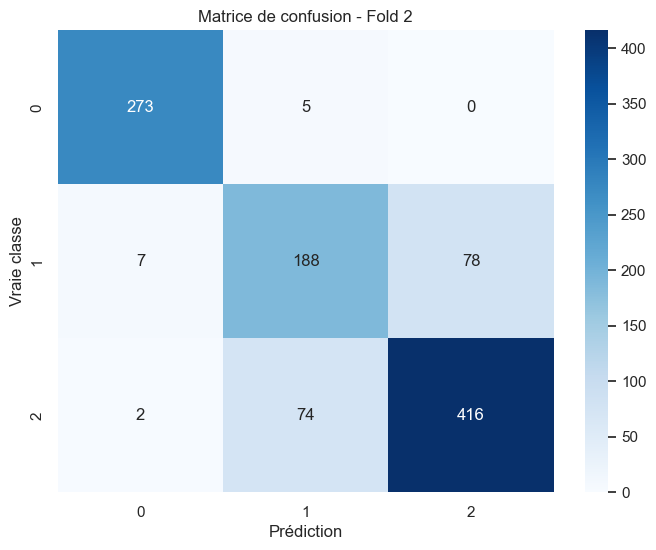

Fold 3/5
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - Precision: 0.6923 - Recall: 0.6034 - accuracy: 0.6569 - loss: 6.4460 - val_Precision: 0.7928 - val_Recall: 0.7555 - val_accuracy: 0.7756 - val_loss: 4.2580 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - Precision: 0.8054 - Recall: 0.7801 - accuracy: 0.7943 - loss: 3.8843 - val_Precision: 0.8207 - val_Recall: 0.7987 - val_accuracy: 0.8063 - val_loss: 3.0876 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - Precision: 0.8233 - Recall: 0.8029 - accuracy: 0.8152 - loss: 2.8987 - val_Precision: 0.7978 - val_Recall: 0.7756 - val_accuracy: 0.7891 - val_loss: 2.5740 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - Precision: 0.8326 - Recall: 0.8183 - accuracy: 0.8278 - loss: 2.3786 - val_Precision: 0.8243 - val_Recall: 0.8188 - val_accuracy: 0.8207 - val_loss: 2.1078 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━

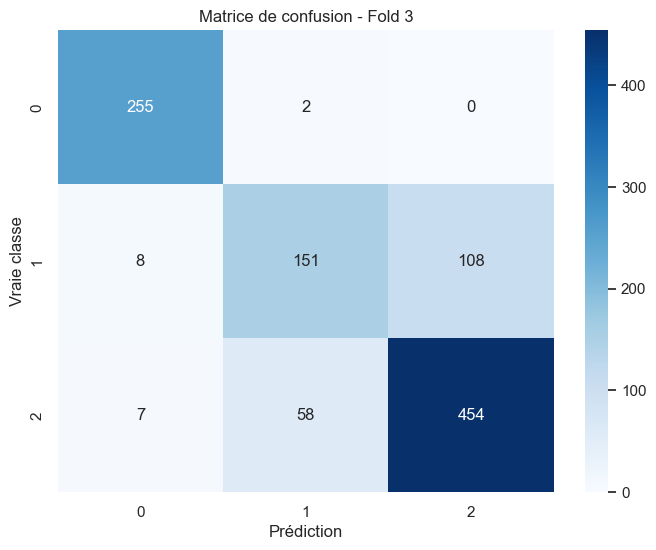

Fold 4/5
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - Precision: 0.6745 - Recall: 0.5786 - accuracy: 0.6388 - loss: 6.4023 - val_Precision: 0.8039 - val_Recall: 0.7862 - val_accuracy: 0.7967 - val_loss: 4.0910 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - Precision: 0.8035 - Recall: 0.7827 - accuracy: 0.7968 - loss: 3.7778 - val_Precision: 0.8186 - val_Recall: 0.8006 - val_accuracy: 0.8111 - val_loss: 2.9595 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - Precision: 0.8065 - Recall: 0.7867 - accuracy: 0.7982 - loss: 2.8237 - val_Precision: 0.8139 - val_Recall: 0.8092 - val_accuracy: 0.8121 - val_loss: 2.4377 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - Precision: 0.8399 - Recall: 0.8322 - accuracy: 0.8369 - loss: 2.2818 - val_Precision: 0.8185 - val_Recall: 0.8044 - val_accuracy: 0.8121 - val_loss: 2.0768 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━

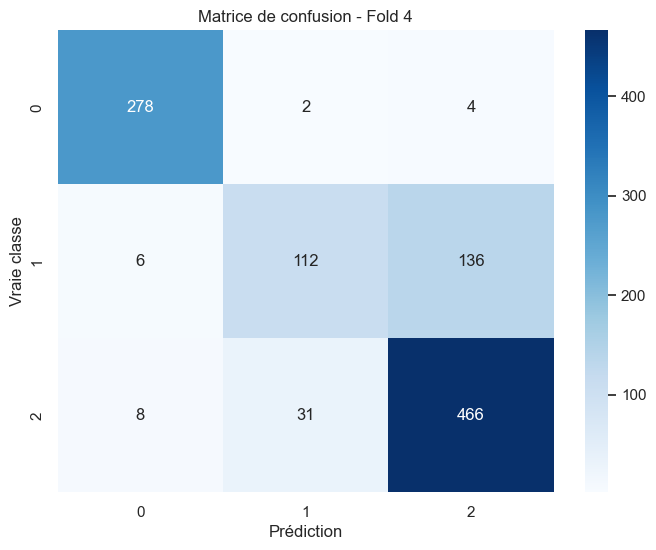

Fold 5/5
Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - Precision: 0.6969 - Recall: 0.5907 - accuracy: 0.6520 - loss: 6.4890 - val_Precision: 0.7892 - val_Recall: 0.7718 - val_accuracy: 0.7795 - val_loss: 4.4372 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - Precision: 0.8235 - Recall: 0.8024 - accuracy: 0.8126 - loss: 4.0371 - val_Precision: 0.8101 - val_Recall: 0.7977 - val_accuracy: 0.8025 - val_loss: 3.2801 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - Precision: 0.8377 - Recall: 0.8225 - accuracy: 0.8318 - loss: 3.0586 - val_Precision: 0.8074 - val_Recall: 0.7958 - val_accuracy: 0.8054 - val_loss: 2.6652 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - Precision: 0.8376 - Recall: 0.8275 - accuracy: 0.8309 - loss: 2.4964 - val_Precision: 0.8180 - val_Recall: 0.8102 - val_accuracy: 0.8169 - val_loss: 2.2377 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━

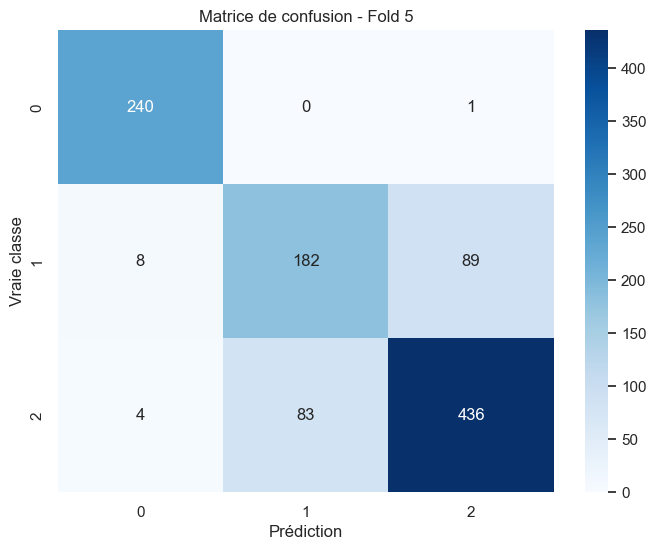


Résultats finaux:
Score moyen: 0.8276 (+/- 0.0072)


In [ ]:
from sklearn.model_selection import KFold
import numpy as np
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, Input
from keras.regularizers import l2
from sklearn.metrics import confusion_matrix, classification_report

# Convertir les données en numpy arrays si ce n'est pas déjà fait
x_train_np = x_train.numpy() if isinstance(x_train, tf.Tensor) else x_train
y_train_np = y_train.numpy() if isinstance(y_train, tf.Tensor) else y_train

# Définir le nombre de folds
n_folds = 5
batch_size = 32
epochs = 15
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
class_names = ['Normal', 'Viral', 'Bacterial']
# Boucle de validation croisée
val_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(x_train_np)):
    print(f'Fold {fold + 1}/{n_folds}')
    
    model = create_model()
    
    # Utiliser les arrays numpy pour l'indexation
    x_train_fold = x_train_np[train_idx]
    y_train_fold = y_train_np[train_idx]
    x_val_fold = x_train_np[val_idx]
    y_val_fold = y_train_np[val_idx]
    
    # Convertir en tensors pour l'entraînement si nécessaire
    x_train_fold = tf.convert_to_tensor(x_train_fold)
    y_train_fold = tf.convert_to_tensor(y_train_fold)
    x_val_fold = tf.convert_to_tensor(x_val_fold)
    y_val_fold = tf.convert_to_tensor(y_val_fold)
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True
    )
    
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.00001
    )
    
    history = model.fit(
        x_train_fold,
        y_train_fold,
        validation_data=(x_val_fold, y_val_fold),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping, reduce_lr]
    )
    
    val_score = model.evaluate(x_val_fold, y_val_fold, verbose=0)
    val_scores.append(val_score[1])
    
    print(f"Fold {fold + 1} - Accuracy: {val_score[1]:.4f}")
    
     # Matrice de confusion avec plus de détails
    y_pred = model.predict(x_val_fold)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_val_fold, axis=1)
    
    
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    
    # Calculer TP, TN, FP, FN pour chaque classe
    n_classes = 3
    metrics = {}
    
    for i in range(n_classes):
        TP = cm[i, i]
        FP = np.sum(cm[:, i]) - TP
        FN = np.sum(cm[i, :]) - TP
        TN = np.sum(cm) - TP - FP - FN
        
        metrics[class_names[i]] = {
            'TP': TP,
            'TN': TN,
            'FP': FP,
            'FN': FN,
            'Precision': TP / (TP + FP) if (TP + FP) > 0 else 0,
            'Recall': TP / (TP + FN) if (TP + FN) > 0 else 0
        }
    
    # Afficher la matrice de confusion
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f'Matrice de confusion - Fold {fold + 1}')
    plt.ylabel('Vraie classe')
    plt.xlabel('Prédiction')
    plt.show()
    
    # Afficher les métriques détaillées
    print(f"\nMétriques détaillées pour le Fold {fold + 1}:")
    for classe, m in metrics.items():
        print(f"\nClasse: {classe}")
        print(f"True Positives (TP): {m['TP']}")
        print(f"True Negatives (TN): {m['TN']}")
        print(f"False Positives (FP): {m['FP']}")
        print(f"False Negatives (FN): {m['FN']}")
        print(f"Precision: {m['Precision']:.4f}")
        print(f"Recall: {m['Recall']:.4f}")
    
    # Afficher le rapport de classification complet
    print("\nRapport de classification détaillé:")
    print(classification_report(y_true_classes, y_pred_classes, 
                              target_names=class_names))
    
    # Extract the training and validation loss values from the history object
    train_loss = history['loss']
    val_loss = history['val_loss']

    # Create a list of epoch numbers (1 to number of epochs)
    epochs = range(1, len(train_loss) + 1)

    # Plot the loss graph
    fig, ax = plt.subplots(figsize=(20,8))
    sns.lineplot(x = epochs, y = train_loss)
    sns.lineplot(x = epochs, y = val_loss)
    ax.set_title('Learning Curve (Loss)')
    ax.set_ylabel('Loss')
    ax.set_xlabel('Epoch')
    ax.set_ylim(0, 0.5)
    ax.legend(['train', 'val'], loc='best')
    plt.show()

    # ⚠️ Assurez-vous que model, X_test et y_test sont bien définis
    y_pred_classes = (y_pred > 0.5).astype(int)  # Pour classification binaire
    y_true = y_test  # S'assurer que y_test est sous la bonne forme

    from sklearn.metrics import roc_curve, auc
    import matplotlib.pyplot as plt

    # ⚠️ Vérifier que model.predict() donne bien des probabilités (entre 0 et 1)
    y_pred_prob = model.predict(x_test)[:, 1]  # Prendre seulement la proba de "Pneumonia"

    # Calcul des valeurs ROC
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)  # y_true = vraies classes
    roc_auc = auc(fpr, tpr)

    # Affichage de la courbe ROC
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonale aléatoire
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taux de faux positifs (FPR)')
    plt.ylabel('Taux de vrais positifs (TPR)')
    plt.title('Courbe ROC - Détection Pneumonie')
    plt.legend(loc='lower right')
    plt.show()


print("\nRésultats finaux:")
print(f"Score moyen: {np.mean(val_scores):.4f} (+/- {np.std(val_scores):.4f})")

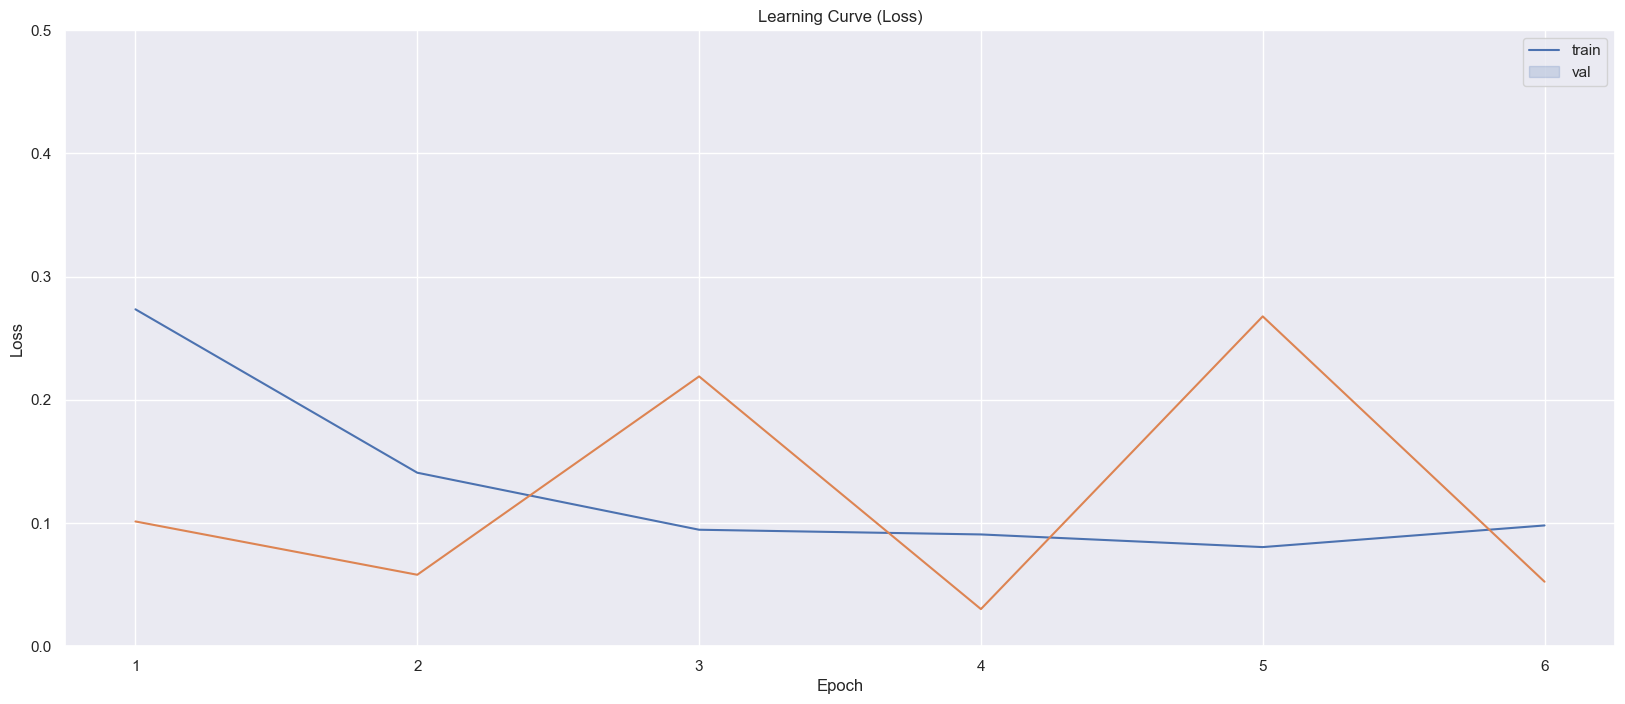

In [55]:
# Extract the training and validation loss values from the history object
train_loss = history['loss']
val_loss = history['val_loss']

# Create a list of epoch numbers (1 to number of epochs)
epochs = range(1, len(train_loss) + 1)

# Plot the loss graph
fig, ax = plt.subplots(figsize=(20,8))
sns.lineplot(x = epochs, y = train_loss)
sns.lineplot(x = epochs, y = val_loss)
ax.set_title('Learning Curve (Loss)')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.set_ylim(0, 0.5)
ax.legend(['train', 'val'], loc='best')
plt.show()



In [52]:
# Save the model
model.save('CNN_model.h5')

20/20 ━━━━━━━━━━━━━━━━━━━━ 59s 3s/step


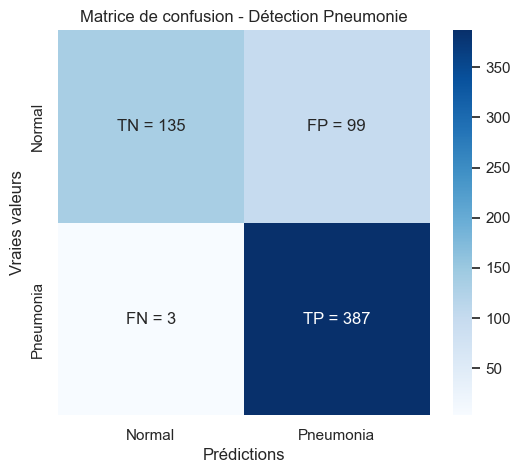

              precision    recall  f1-score   support

      Normal       0.98      0.58      0.73       234
   Pneumonia       0.80      0.99      0.88       390

    accuracy                           0.84       624
   macro avg       0.89      0.78      0.80       624
weighted avg       0.86      0.84      0.82       624



In [65]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ⚠️ Assurez-vous que model, X_test et y_test sont bien définis
y_pred = model.predict(x_test)
y_pred_classes = (y_pred > 0.5).astype(int)  # Pour classification binaire
y_true = y_test  # S'assurer que y_test est sous la bonne forme

# Labels des classes
class_names = ["Normal", "Pneumonia"]

y_true = np.argmax(y_true, axis=1)  # Convertit [1, 0] en 0 et [0, 1] en 1
y_pred_classes = np.argmax(y_pred, axis=1)  # Même conversion pour les prédictions


# Matrice de confusion
cm = confusion_matrix(y_true, y_pred_classes)

# Définir les annotations avec TN, FP, FN, TP
labels = np.array([["TN = {}".format(cm[0,0]), "FP = {}".format(cm[0,1])],
                   ["FN = {}".format(cm[1,0]), "TP = {}".format(cm[1,1])]])

# Affichage de la heatmap avec annotations
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Matrice de confusion - Détection Pneumonie")
plt.xlabel("Prédictions")
plt.ylabel("Vraies valeurs")
plt.show()

# Rapport de classification
print(classification_report(y_true, y_pred_classes, target_names=class_names))


20/20 ━━━━━━━━━━━━━━━━━━━━ 53s 3s/step


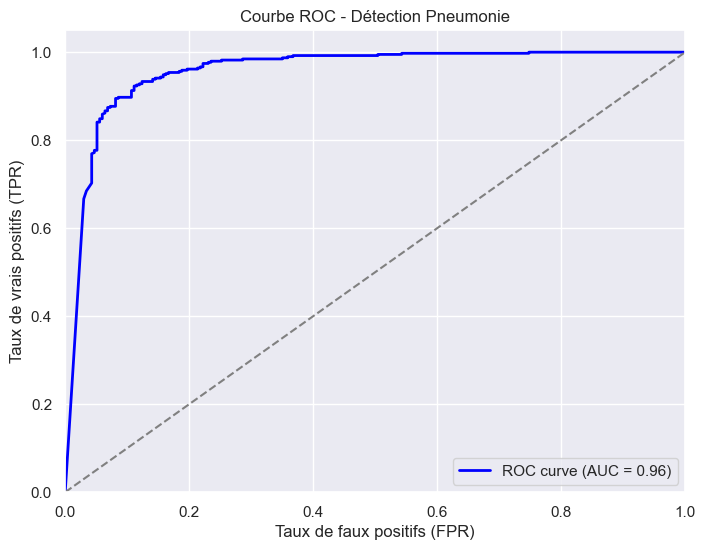

In [68]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ⚠️ Vérifier que model.predict() donne bien des probabilités (entre 0 et 1)
y_pred_prob = model.predict(x_test)[:, 1]  # Prendre seulement la proba de "Pneumonia"

# Calcul des valeurs ROC
fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)  # y_true = vraies classes
roc_auc = auc(fpr, tpr)

# Affichage de la courbe ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonale aléatoire
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.title('Courbe ROC - Détection Pneumonie')
plt.legend(loc='lower right')
plt.show()
